In [ ]:
from langgraph.graph import StateGraph,START,END # (Dummy nodes)
from typing import TypedDict

In [ ]:
# Define State
class BMIState(TypedDict):
  weight_kg:float
  height_m:float
  bmi:float
  category:str

In [ ]:
def calculate_bmi(state:BMIState)->BMIState:
  weight = state['weight_kg']
  height = state['height_m']

  bmi = weight/(height)**2
  state['bmi'] = round(bmi,2)
  return state

In [ ]:
def label_bmi(state:BMIState)->BMIState:

    bmi = state['bmi']

    if bmi < 18.5:
        state["category"] = "Underweight"
    elif 18.5 <= bmi < 25:
        state["category"] = "Normal"
    elif 25 <= bmi < 30:
        state["category"] = "Overweight"
    else:
        state["category"] = "Obese"

    return state

In [ ]:
# Define graph
graph = StateGraph(BMIState)

# Define node
graph.add_node('BMI_Calculator',calculate_bmi)
graph.add_node('BMI_Labeler', label_bmi)

# define edges
graph.add_edge(START,'BMI_Calculator')
graph.add_edge('BMI_Calculator','BMI_Labeler')
graph.add_edge('BMI_Labeler',END)

In [ ]:
# Compile the graph
workflow = graph.compile()

In [ ]:
# Execute the graph
initial_state = {'weight_kg':72,'height_m':1.77}

final_state = workflow.invoke(initial_state)

print(final_state)

{'weight_kg': 72, 'height_m': 1.77, 'bmi': 22.98, 'category': 'Normal'}


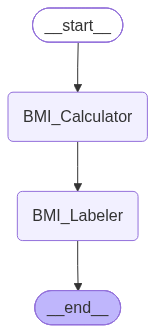

In [ ]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())